# v12 R: Hindi-only fix + the lesion tests on the SECOND related model (seed 1)
- **Hindi-only fix:** in v11 A the Hindi-only model's self was found on Hindi, Chinese and Arabic text, but that model only ever saw Hindi. Redone with the self found on Hindi only (phases 10, 30, 45, 60). Result: `analysis/v11/static_hindi_fix/`.
- **Seed 1 of the related run** (`v8_indic_continual_s1`, an independently trained model): sizes (phases 5 to 16), count-matched lesions without training (phases 10 to 15), then lesion + train the next language for 1,000 steps (start points 10 to 15; training seed 0 first, then seed 1).
  Results: `analysis/v11/sizes_s1/`, `static_s1/`, `train_next_s1/`.

Progress: `tail -f logs/v12_R_seed1.log`

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = os.environ.get("CML_GPU", "0"); LOG = "v12_R_seed1"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
FILES, HF_REPO = [], None
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)
if not FILES:
    print("could not list the HF repo: only checkpoints already on this machine will be used")

def have(run, ph):
    return bool(glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"))

def get(run, phases):
    """download what is missing; returns the phases that are on this machine afterwards"""
    ok = []
    for ph in phases:
        if not have(run, ph):
            name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
            if name:
                try:
                    hf_hub_download(HF_REPO, name[0], local_dir="runs")
                except Exception as e:
                    print("download failed:", run, ph, type(e).__name__, e)
        if have(run, ph):
            ok.append(ph)
        else:
            print("not available (not here, not on HF):", run, ph)
    return ok

def run(langset, script, *cmd):
    """one call of a script; output shown here AND appended to logs/<LOG>.log (watch with: tail -f logs/<LOG>.log)"""
    env = {**os.environ, "CML_LANGSET": langset}; os.makedirs("logs", exist_ok=True)
    p = subprocess.Popen([sys.executable, "-u", script, "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    with open(f"logs/{LOG}.log", "a") as log:
        for line in p.stdout:
            print(line, end=""); log.write(line); log.flush()
    p.wait(); print("exit code", p.returncode)

def summary(script, part, out=None):
    cmd = [sys.executable, script, "--summarize", "--part", part] + (["--out", out] if out else [])
    r = subprocess.run(cmd, capture_output=True, text=True); print(r.stdout[-14000:]); print(r.stderr[-3000:])

def show(*paths):
    for f in paths:
        if os.path.exists(f): display(Image(f))

DIST, HIN, MIX, REL, REL1 = "v4b_continual_s0", "v4b_only_hi_s0", "v6b_mixed_s0", "v8_indic_continual_s0", "v8_indic_continual_s1"
print("GPU", GPU)

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


GPU 1


In [2]:
f = "analysis/v11/static_hindi_fix/static.csv"
if os.path.exists(f): os.remove(f)                                  # this part has no resume: start clean
ok = get(HIN, [10, 30, 45, 60])
if ok:
    run("distant", "core_v11.py", "--part", "static", "--out", "static_hindi_fix", "--family", "hindi", "--self_langs", "hi", "--eval_langs", "hi",
        "--model", f"hindi={HIN}:" + ",".join(str(p) for p in ok))
summary("core_v11.py", "static", "static_hindi_fix")

p010_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p030_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p060_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

hindi phase 10 (hi): intact loss hi 1.127 | chrF hi 51.7
  count-matched n per layer (n_max = smaller group): enc0:1125 enc1:1171 enc2:1159 enc3:1193 dec0:1098 dec1:1175 dec2:1213 dec3:870


  all 8 layers, loss rise (average of languages and draws):
cond     look@0.5  self@0.5  self@1.0  task@0.5  task@1.0
mode                                                     
lesion      0.338     0.627     3.970     0.335     1.150
silence     0.279     0.568     3.567     0.296     0.964
  restored model check: loss differs from intact by 0.00000 (should be ~0) | 42s


hindi phase 30 (hi): intact loss hi 1.141 | chrF hi 51.8
  count-matched n per layer (n_max = smaller group): enc0:1198 enc1:879 enc2:879 enc3:1103 dec0:1149 dec1:1019 dec2:1026 dec3:1020


... (3 outputs left out)

hindi phase 60 (hi): intact loss hi 1.155 | chrF hi 51.7
  count-matched n per layer (n_max = smaller group): enc0:1103 enc1:750 enc2:731 enc3:930 dec0:1181 dec1:914 dec2:897 dec3:1021


  all 8 layers, loss rise (average of languages and draws):
cond     look@0.5  self@0.5  self@1.0  task@0.5  task@1.0
mode                                                     
lesion      0.467     0.969     3.995     0.518     1.546
silence     0.348     0.781     3.199     0.420     1.129
  restored model check: loss differs from intact by 0.00000 (should be ~0) | 37s
done


exit code 0


=== static (no training): loss rise on the model's languages; one comparison = one checkpoint x one scope x one draw (average of the languages) ===

--- self vs task (count-matched)
family        scope    mode dose   self   task  ratio self_worse  sign_p
 hindi all 8 layers  lesion  0.5 0.8466 0.3744 2.2611        8/8  0.0039
 hindi all 8 layers  lesion  1.0 3.9454 1.3957 2.8269        8/8  0.0039
 hindi all 8 layers silence  0.5 0.6962 0.3100 2.2457        8/8  0.0039
 hindi all 8 layers silence  1.0 3.3777 1.0825 3.1202        8/8  0.0039
 hindi    one layer  lesion  0.5 0.0547 0.0330 1.6551      58/64  0.0000
 hindi    one layer  lesion  1.0 0.1612 0.0912 1.7669      57/64  0.0000
 hindi    one layer silence  0.5 0.0465 0.0279 1.6662      54/64  0.0000
 hindi    one layer silence  1.0 0.1175 0.0751 1.5636      60/64  0.0000

--- self vs look (count-matched)
family        scope    mode dose   self   look  ratio self_worse  sign_p
 hindi all 8 layers  lesion  0.5 0.8466 0.3958 2.1392 

In [3]:
for f in ["analysis/v11/sizes_s1/sizes.csv", "analysis/v11/static_s1/static.csv"]:
    if os.path.exists(f): os.remove(f)
ok = get(REL1, list(range(5, 17)))
if ok:
    run("indic", "core_v11.py", "--part", "sizes", "--out", "sizes_s1", "--family", "related_s1", "--model", f"related_s1={REL1}:" + ",".join(str(p) for p in ok))
summary("core_v11.py", "sizes", "sizes_s1")
ok = get(REL1, [10, 11, 12, 13, 14, 15])
if ok:
    run("indic", "core_v11.py", "--part", "static", "--out", "static_s1", "--family", "related_s1", "--model", f"related_s1={REL1}:" + ",".join(str(p) for p in ok))
summary("core_v11.py", "static", "static_s1")

p005_gu.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p006_pa.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p007_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p008_gu.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p009_pa.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p010_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

... (29 outputs left out)

related_s1 phase 15 (pa): intact loss hi 3.221, gu 3.150, pa 1.890 | chrF hi 37.9, gu 38.5, pa 43.9
  count-matched n per layer (n_max = smaller group): enc0:1229 enc1:1091 enc2:1163 enc3:1173 dec0:899 dec1:1210 dec2:1269 dec3:677


  all 8 layers, loss rise (average of languages and draws):
cond     look@0.5  self@0.5  self@1.0  task@0.5  task@1.0
mode                                                     
lesion      0.235     0.463     2.003     0.274     0.857
silence     0.137     0.364     1.814     0.194     0.583
  restored model check: loss differs from intact by 0.00000 (should be ~0) | 106s
done


exit code 0


=== static (no training): loss rise on the model's languages; one comparison = one checkpoint x one scope x one draw (average of the languages) ===

--- self vs task (count-matched)
    family        scope    mode dose   self   task  ratio self_worse  sign_p
related_s1 all 8 layers  lesion  0.5 0.5129 0.2259 2.2706      12/12  0.0002
related_s1 all 8 layers  lesion  1.0 2.8494 1.2217 2.3323       9/12  0.0730
related_s1 all 8 layers silence  0.5 0.4065 0.1562 2.6018      12/12  0.0002
related_s1 all 8 layers silence  1.0 2.6320 1.0453 2.5179       9/12  0.0730
related_s1    one layer  lesion  0.5 0.0398 0.0220 1.8118      86/96  0.0000
related_s1    one layer  lesion  1.0 0.0926 0.0692 1.3379      81/96  0.0000
related_s1    one layer silence  0.5 0.0317 0.0144 2.1992      83/96  0.0000
related_s1    one layer silence  1.0 0.0770 0.0671 1.1483      85/96  0.0000

--- self vs look (count-matched)
    family        scope    mode dose   self   look  ratio self_worse  sign_p
related_s1 all

start model: related_s1_10 = v8_indic_continual_s1 phase 10 (last trained on hi) | languages hi, gu, pa


  enc0: working 2560, self 1403, task 1157 -> count-matched n_max 1157
  enc1: working 2560, self 1197, task 1363 -> count-matched n_max 1197
  enc2: working 2560, self 1257, task 1303 -> count-matched n_max 1257
  enc3: working 2560, self 1440, task 1120 -> count-matched n_max 1120
  dec0: working 2560, self 1659, task 901 -> count-matched n_max 901
  dec1: working 2560, self 1193, task 1367 -> count-matched n_max 1193
  dec2: working 2560, self 1266, task 1294 -> count-matched n_max 1266
  dec3: working 2560, self 1879, task 681 -> count-matched n_max 681
  self found in 6s


  next language = gu (phase 11 of the normal schedule)
runs to do in this call: 6 (mode lesion; conditions ['none', 'self@1.0', 'task@1.0', 'self@0.5', 'task@0.5', 'look@0.5']; seeds [0]; finished runs are skipped)


  related_s1_10 | next | none    | none      | seed 0 | 0 neurons | loss 4.459 -> 2.192 | chrF 31.0 -> 43.1 | 101s | left in this call: 5 runs, about 8 min


  related_s1_10 | next | lesion  | self@1.0  | seed 0 | 8772 neurons | loss 8.398 -> 2.304 | chrF 2.0 -> 41.0 | 99s | left in this call: 4 runs, about 7 min


  related_s1_10 | next | lesion  | task@1.0  | seed 0 | 8772 neurons | loss 4.933 -> 2.273 | chrF 21.9 -> 43.1 | 99s | left in this call: 3 runs, about 5 min


... (112 outputs left out)

  related_s1_15 | next | lesion  | task@0.5  | seed 1 | 4355 neurons | loss 3.658 -> 1.710 | chrF 26.2 -> 49.1 | 98s | left in this call: 1 runs, about 2 min


  related_s1_15 | next | lesion  | look@0.5  | seed 1 | 4355 neurons | loss 3.540 -> 1.721 | chrF 35.2 -> 49.4 | 98s | left in this call: 0 runs, about 0 min
done


exit code 0


=== train (train_next_s1): held-out loss on the trained language MINUS the untouched model's, same start and seed ===
average over starts and seeds; step 0 = right after the intervention, before any training
step                            0       100     300     1000
family     mode   dose group                                
related_s1 lesion 0.5  look   0.2379  0.0987  0.0655  0.0474
                       self   0.5558  0.1310  0.0845  0.0546
                       task   0.2160  0.0886  0.0615  0.0450
                  1.0  self   2.5932  0.3675  0.2204  0.1400
                       task   1.1234  0.2194  0.1507  0.1055

--- self vs task: in how many runs is the self version worse (one run = one start x one seed)
    family   mode dose  step  mean_gap self_worse  sign_p
related_s1 lesion  0.5     0    0.3398      12/12  0.0002
related_s1 lesion  0.5   100    0.0424      12/12  0.0002
related_s1 lesion  0.5   300    0.0230      12/12  0.0002
related_s1 lesion  0.5  1000    0.0096

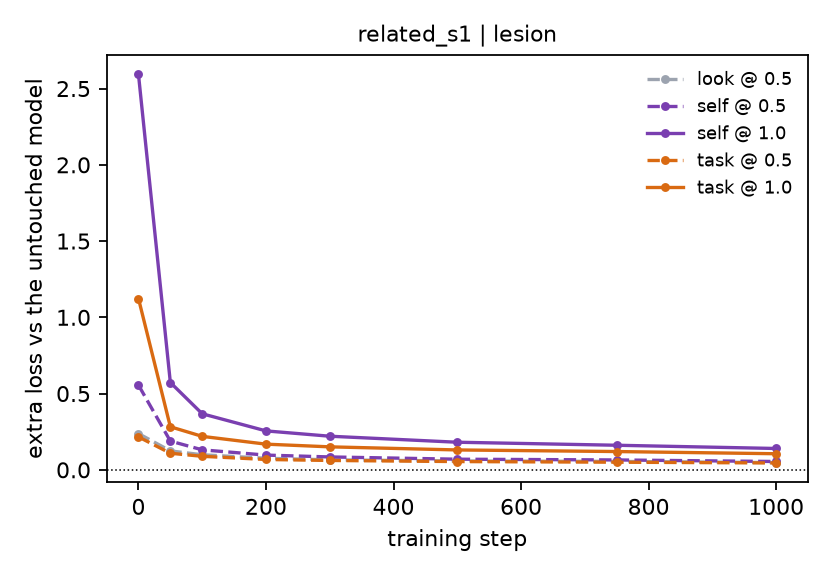

In [4]:
for seeds in ["0", "1"]:
    for ph in get(REL1, [10, 11, 12, 13, 14, 15]):
        run("indic", "core_v11.py", "--part", "train", "--task", "next", "--mode", "lesion", "--out", "train_next_s1", "--family", "related_s1",
            "--model", f"related_s1_{ph}={REL1}:{ph}", "--seeds", seeds)
    summary("core_v11.py", "train", "train_next_s1")
show("analysis/v11/train_next_s1/curves.png")